# EEG frequency bands & sleep oscillation coupling

This notebook visualizes, in order:

| # | Rhythm | Band definition | Simulated frequency |
|---|---|---|---|
| 1 | **Beta** | 12–30 Hz | 20 Hz |
| 2 | **Alpha** | 8–13 Hz | 10 Hz |
| 3 | **Theta** | 4–7 Hz | 6 Hz |
| 4 | **Delta** | < 4 Hz | 3 Hz |
| 5 | **Slow oscillations (SO)** | ≤ 2 Hz | 1 Hz |

and then the two levels of the hierarchical sleep-oscillation nesting:

* **Thalamocortical spindles (13–16 Hz, simulated at 15 Hz)** grouped into the depolarizing **up-states** of cortical slow oscillations (1 Hz)
* **Hippocampal ripples (80–200 Hz, simulated at 150 Hz)** grouped into the **troughs** of thalamocortical spindles

Every rhythm is simulated at **one steady frequency** (no frequency variation). Spindles and ripples still wax and wane in
amplitude, because they are by definition transient bursts, but their carrier frequency is fixed.

By default the signals are **simulated** (pure sinusoids at the frequencies above on a small 1/f background, and an
SO → spindle → ripple generator with known ground truth), so every figure is reproducible. The analysis part (filtering, Hilbert phase/amplitude, event detection,
phase histograms, modulation index) is the same pipeline you would run on real data — set `USE_REAL_DATA = True` in the settings
to point it at your own recording.

**Notes on the band definitions**
* The ranges are used exactly as specified, so Alpha and Beta share 12–13 Hz, and SO (≤ 2 Hz) is a subset of Delta (< 4 Hz).
* "< 4 Hz" and "≤ 2 Hz" have no lower bound in the definition; a practical high-pass edge (`DELTA_LOW_HZ`, `SO_LOW_HZ`) is set in the settings to avoid DC drift.
* Spindles are restricted to the fast-spindle range given (13–16 Hz); slow frontal spindles (~9–12 Hz) are not modelled.

**Key references:** Mölle et al. 2002 *J Neurosci* (spindle grouping by SO); Siapas & Wilson 1998 *Neuron* and Sirota et al. 2003 *PNAS*
(ripple–spindle coordination); Staresina et al. 2015 *Nat Neurosci* (hierarchical SO–spindle–ripple nesting in human hippocampus);
Tort et al. 2010 *J Neurophysiol* (modulation index).

## 0 · Settings
Everything you may want to change lives in this cell. Re-run the notebook (*Kernel → Restart & Run All*) after editing.

In [31]:
# =====================================================================
#                              SETTINGS
# =====================================================================

# ---------- Data source ----------
USE_REAL_DATA     = False          # False -> simulated data, True -> load a file with MNE
REAL_DATA_PATH    = "my_sleep_recording.edf"   # any format mne.io.read_raw() understands
REAL_CORTEX_CH    = "C3"           # scalp / cortical channel (SO, spindles, bands)
REAL_HPC_CH       = None           # hippocampal (depth/LFP) channel for ripples; None -> use cortex channel
REAL_CROP_S       = (0, 600)       # (start, stop) seconds to analyse; ideally NREM N2/N3 epochs only

# ---------- Simulation ----------
FS                = 1000           # sampling rate (Hz) – must be > 2 x RIPPLE_BAND[1]
DURATION_S        = 120            # length of the simulated recording (s)
RANDOM_SEED       = 7
BACKGROUND_EXP    = 1.0            # exponent of the 1/f^x background (1 = pink noise)
BACKGROUND_UV     = 3.0            # std of the cortical background (µV)
HPC_BACKGROUND_UV = 4.0            # std of the hippocampal background (µV)

# ---------- Frequency bands (shown in THIS order) ----------
DELTA_LOW_HZ = 0.5                 # practical lower edge for "< 4 Hz"
SO_LOW_HZ    = 0.16                # practical lower edge for "<= 2 Hz"
BANDS = {
    #  name                  steady frequency   band definition (reference)    amplitude (µV)
    "Beta":               {"freq_hz": 20,      "range": (12, 30),             "amp_uv": 5},
    "Alpha":              {"freq_hz": 10,      "range": (8, 13),              "amp_uv": 15},
    "Theta":              {"freq_hz": 6,       "range": (4, 7),               "amp_uv": 12},
    "Delta":              {"freq_hz": 3,       "range": (DELTA_LOW_HZ, 4),    "amp_uv": 25},
    "Slow oscillations":  {"freq_hz": 1,       "range": (SO_LOW_HZ, 2),       "amp_uv": 40},
}
BAND_WINDOW_S   = 2.0              # seconds of signal shown in the band decomposition
BAND_WINDOW_T0  = 10.0             # start time of that window (s)
FILTER_ORDER    = 4                # Butterworth order (applied forward-backward -> zero phase)
PSD_WINDOW_S    = 8.0              # Welch segment length (s)
PSD_FMAX_HZ     = 40               # x-limit of the band spectrum

# ---------- SO -> spindle -> ripple simulation ----------
SO_FREQ_HZ         = 1.0           # steady SO frequency
SO_FREQ_SD_HZ      = 0.0           # cycle-to-cycle frequency jitter (0 = perfectly steady)
SO_AMP_UV          = 70            # SO amplitude (µV)
UP_STATE_POLARITY  = +1            # +1: up-state = surface-positive half-wave; -1: surface-negative
SPINDLE_BAND       = (13, 16)      # Hz (band used for filtering / detection)
SPINDLE_FREQ_HZ    = 15            # steady spindle frequency
SPINDLE_DUR_S      = 0.7           # full width at half maximum of the spindle envelope
SPINDLE_AMP_UV     = 20
SPINDLE_PROB       = 0.35          # fraction of SO up-states that carry a spindle
SPINDLE_LAG_SD_S   = 0.08          # timing jitter of spindle centre around the up-state peak
RIPPLE_BAND        = (80, 200)     # Hz (band used for filtering / detection)
RIPPLE_FREQ_HZ     = 150           # steady ripple frequency
RIPPLE_DUR_S       = 0.035         # FWHM of the ripple envelope
RIPPLE_AMP_UV      = 22
RIPPLE_PROB        = 0.35          # probability of a ripple at each high-amplitude spindle trough
RIPPLE_JITTER_S    = 0.004         # timing jitter around the spindle trough

# ---------- Triple-coupling schematic (section B0) ----------
TRIPLE_SPINDLE_LAG_DEG          = -40    # SO phase at the spindle peak (0° = SW peak / up-state)
TRIPLE_RIPPLE_SPINDLE_PHASE_DEG = 180    # spindle phase at the ripple peak (0° = spindle peak, ±180° = trough)
TRIPLE_RIPPLE_CYCLE             = 0      # which spindle cycle (relative to the spindle centre) holds the ripple
TRIPLE_SO_AMP_UV                = 70
TRIPLE_SPINDLE_AMP_UV           = 15
TRIPLE_SPINDLE_FWHM_S           = 0.5
TRIPLE_RIPPLE_AMP_UV            = 6
TRIPLE_RIPPLE_FWHM_S            = 0.03
TRIPLE_ZOOM_MS                  = 100    # ± half-width of the spindle/ripple zoom

# ---------- Event detection / analysis ----------
SPINDLE_THRESH_K   = 3.0           # envelope threshold: median + k * robust SD (1.4826*MAD)
SPINDLE_MIN_DUR_S  = 0.3
SPINDLE_MAX_DUR_S  = 3.0
SPINDLE_SMOOTH_S   = 0.1
RIPPLE_THRESH_K    = 5.0
RIPPLE_MIN_DUR_S   = 0.015
RIPPLE_SMOOTH_S    = 0.01
PHASE_BINS         = 18            # bins for phase histograms / modulation index
SO_LOCK_WIN_S      = 1.5           # ± window for spindle-locked averages
RIPPLE_LOCK_WIN_S  = 0.25          # ± window for ripple-locked averages

# ---------- Figures ----------
OVERVIEW_WINDOW_S  = (20, 40)      # time range of the coupling overview figure
ZOOM_EVENT         = 0             # which nested SO-spindle-ripple event to zoom into
FIG_WIDTH          = 13            # inches
DPI                = 110
FONT_SIZE          = 10
LINE_WIDTH         = 1.1
COLORS = {                         # validated categorical palette, fixed order
    "Beta": "#2a78d6", "Alpha": "#eb6834", "Theta": "#1baf7a",
    "Delta": "#eda100", "Slow oscillations": "#e87ba4",
    "so": "#2a78d6", "spindle": "#eb6834", "ripple": "#1baf7a",
    "raw": "#8a8984", "text": "#0b0b0b", "muted": "#52514e", "grid": "#e4e3df",
    "band": "#e9e8e4",           # grey band marking a coupling phase in the schematic
}
SAVE_FIGURES       = False
FIG_DIR            = "figures"
FIG_FORMAT         = "png"         # png | svg | pdf

## 1 · Setup & helper functions

In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import ConnectionPatch, Rectangle
from scipy.signal import butter, sosfiltfilt, hilbert, welch

rng = np.random.default_rng(RANDOM_SEED)
plt.rcParams.update({
    "figure.dpi": DPI, "font.size": FONT_SIZE, "lines.linewidth": LINE_WIDTH,
    "axes.edgecolor": COLORS["muted"], "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": FONT_SIZE + 1,
    "legend.frameon": False, "figure.facecolor": "white",
})
if SAVE_FIGURES:
    os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{FIG_FORMAT}"), bbox_inches="tight")

def bandpass(x, lo, hi, fs=FS, order=FILTER_ORDER):
    """Zero-phase Butterworth band-pass (low-pass if lo is None)."""
    if lo is None or lo <= 0:
        sos = butter(order, hi, btype="lowpass", fs=fs, output="sos")
    else:
        sos = butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def colored_noise(n, exponent=1.0, rng=rng):
    """Gaussian noise with a 1/f^exponent power spectrum, unit variance."""
    spec = rng.standard_normal(n // 2 + 1) + 1j * rng.standard_normal(n // 2 + 1)
    f = np.fft.rfftfreq(n, 1 / FS); f[0] = f[1]
    x = np.fft.irfft(spec / f ** (exponent / 2), n)
    return (x - x.mean()) / x.std()

def smooth(x, win_s, fs=FS):
    w = max(1, int(win_s * fs))
    return np.convolve(x, np.ones(w) / w, mode="same")

def detect_events(env, k, min_dur, max_dur=np.inf, fs=FS):
    """Threshold an amplitude envelope at median + k * robust SD (outlier-resistant,
    so frequent events do not inflate their own threshold).
    Returns list of (start, stop, peak) sample indices and the threshold."""
    med = np.median(env)
    thr = med + k * 1.4826 * np.median(np.abs(env - med))
    above = np.r_[False, env > thr, False]
    edges = np.flatnonzero(np.diff(above.astype(int)))
    events = []
    for s, e in zip(edges[::2], edges[1::2]):
        dur = (e - s) / fs
        if min_dur <= dur <= max_dur:
            events.append((s, e, s + int(np.argmax(env[s:e]))))
    return events, thr

def circ_stats(phases):
    """Mean direction (rad), resultant length R and Rayleigh p-value."""
    n = len(phases)
    if n == 0:
        return np.nan, np.nan, np.nan
    z = np.mean(np.exp(1j * phases))
    R = np.abs(z); Rn = R * n
    p = np.exp(np.sqrt(1 + 4 * n + 4 * (n**2 - Rn**2)) - (1 + 2 * n))
    return np.angle(z), R, min(p, 1.0)

def modulation_index(phase, amp, nbins=PHASE_BINS):
    """Tort et al. (2010) modulation index + mean amplitude per phase bin."""
    edges = np.linspace(-np.pi, np.pi, nbins + 1)
    idx = np.clip(np.digitize(phase, edges) - 1, 0, nbins - 1)
    mean_amp = np.array([amp[idx == k].mean() if np.any(idx == k) else 0 for k in range(nbins)])
    P = mean_amp / mean_amp.sum()
    mi = (np.log(nbins) + np.sum(P * np.log(P + 1e-12))) / np.log(nbins)
    centers = (edges[:-1] + edges[1:]) / 2
    return mi, centers, mean_amp

def peri_event(x, idx, half_win_s, fs=FS):
    h = int(half_win_s * fs)
    segs = np.array([x[i - h:i + h + 1] for i in idx if h <= i < len(x) - h])
    return np.arange(-h, h + 1) / fs, segs

def label_panel(ax, letter):
    ax.text(-0.06, 1.04, letter, transform=ax.transAxes, fontweight="bold",
            fontsize=FONT_SIZE + 2, va="bottom", ha="right", color=COLORS["text"])

print("helpers ready")

helpers ready


## 2 · Generate (or load) the data

The simulated cortical channel is the sum of
* a 1/f background,
* one steady sinusoid per band (20, 10, 6, 3 and 1 Hz; used in Part A),
* a slow oscillation with spindles placed on its up-states (used in Part B).

A separate simulated **hippocampal** channel contains ripples placed into the troughs of the spindles.

In [33]:
if USE_REAL_DATA:
    import mne
    raw = mne.io.read_raw(REAL_DATA_PATH, preload=True, verbose="error")
    raw.crop(*REAL_CROP_S).resample(FS, verbose="error")
    cortex = raw.get_data(picks=[REAL_CORTEX_CH])[0] * 1e6          # V -> µV
    hpc = raw.get_data(picks=[REAL_HPC_CH])[0] * 1e6 if REAL_HPC_CH else cortex.copy()
    t = np.arange(cortex.size) / FS
    truth = None
    band_mix = cortex
    band_components = None          # real data: components are obtained by band-pass filtering
else:
    n = int(DURATION_S * FS)
    t = np.arange(n) / FS

    # ---- Part A: band-limited activity on a 1/f background ----
    background = BACKGROUND_UV * colored_noise(n, BACKGROUND_EXP)
    band_mix = background.copy()
    band_components = {}
    for name, b in BANDS.items():
        # one steady sinusoid per band: constant frequency and amplitude
        comp = b["amp_uv"] * np.sin(2 * np.pi * b["freq_hz"] * t)
        band_components[name] = comp
        band_mix += comp

    # ---- Part B: SO -> spindle -> ripple generator ----
    # slow oscillation with cycle-to-cycle frequency jitter
    n_cyc = int(DURATION_S * SO_FREQ_HZ * 2)
    freqs = np.clip(rng.normal(SO_FREQ_HZ, SO_FREQ_SD_HZ, n_cyc), 0.4, 2.0)
    cyc_edges = np.r_[0, np.cumsum(1 / freqs)]
    k = np.searchsorted(cyc_edges, t, side="right") - 1
    so_phase_true = 2 * np.pi * (k + (t - cyc_edges[k]) * freqs[k])   # 0, 2π, … = up-state peak
    so = UP_STATE_POLARITY * SO_AMP_UV * np.cos(so_phase_true)
    up_peaks_t = cyc_edges[:-1][cyc_edges[:-1] < DURATION_S]

    spindles = np.zeros(n); ripples = np.zeros(n)
    sp_sigma = SPINDLE_DUR_S / (2 * np.sqrt(2 * np.log(2)))
    rp_sigma = RIPPLE_DUR_S / (2 * np.sqrt(2 * np.log(2)))
    truth = {"up_peaks": up_peaks_t, "spindle_centers": [], "ripple_centers": []}
    for tu in up_peaks_t[1:-1]:
        if rng.random() > SPINDLE_PROB:
            continue
        c = tu + rng.normal(0, SPINDLE_LAG_SD_S)
        f_sp = SPINDLE_FREQ_HZ
        ph0 = rng.uniform(0, 2 * np.pi)
        sl = slice(max(0, int((c - 4 * sp_sigma) * FS)), min(n, int((c + 4 * sp_sigma) * FS)))
        tt = t[sl]
        spindles[sl] += SPINDLE_AMP_UV * np.exp(-(tt - c) ** 2 / (2 * sp_sigma**2)) * np.cos(2 * np.pi * f_sp * (tt - c) + ph0)
        truth["spindle_centers"].append(c)
        # troughs of this spindle: carrier phase = π
        kk = np.arange(-30, 31)
        troughs = c + (np.pi - ph0 + 2 * np.pi * kk) / (2 * np.pi * f_sp)
        troughs = troughs[np.abs(troughs - c) < 1.0 * sp_sigma * 1.18]   # where envelope > ~50 %
        for tr in troughs:
            if rng.random() > RIPPLE_PROB:
                continue
            cr = tr + rng.normal(0, RIPPLE_JITTER_S)
            f_r = RIPPLE_FREQ_HZ
            slr = slice(max(0, int((cr - 4 * rp_sigma) * FS)), min(n, int((cr + 4 * rp_sigma) * FS)))
            ttr = t[slr]
            ripples[slr] += RIPPLE_AMP_UV * np.exp(-(ttr - cr) ** 2 / (2 * rp_sigma**2)) * np.cos(2 * np.pi * f_r * (ttr - cr))
            truth["ripple_centers"].append(cr)

    cortex = so + spindles + BACKGROUND_UV * colored_noise(n, BACKGROUND_EXP)
    hpc = ripples + HPC_BACKGROUND_UV * colored_noise(n, 0.5)
    print(f"simulated {DURATION_S} s @ {FS} Hz: {len(up_peaks_t)} SO cycles, "
          f"{len(truth['spindle_centers'])} spindles, {len(truth['ripple_centers'])} ripples")

simulated 120 s @ 1000 Hz: 120 SO cycles, 36 spindles, 117 ripples


# Part A · EEG frequency bands
## A1 · The five rhythms (Beta → Alpha → Theta → Delta → Slow oscillations)
Top row: the broadband signal (sum of all rhythms + background). Each row below is one rhythm at its steady frequency.
All rows share the same time axis, so the number of cycles per second can be counted directly.
(The simulated components are shown directly rather than filtered back out of the mix: the band definitions overlap, e.g. a
0.5–4 Hz delta filter would also pass the 1 Hz slow oscillation. With real data the band-pass filtered signal is shown instead.)

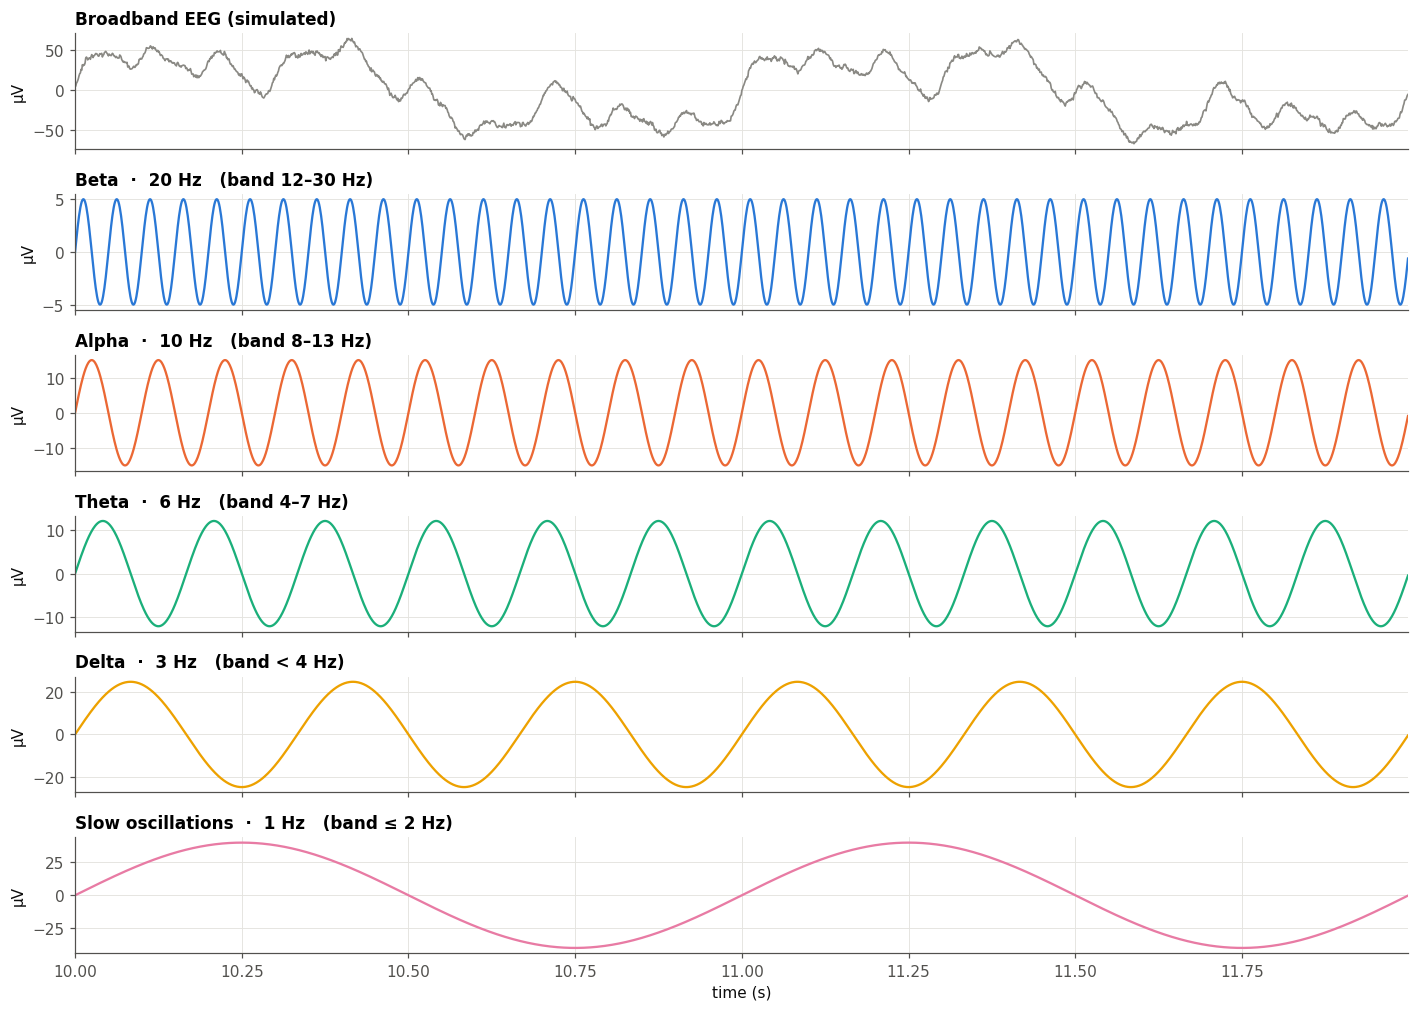

In [34]:
names = list(BANDS)
sl = slice(int(BAND_WINDOW_T0 * FS), int((BAND_WINDOW_T0 + BAND_WINDOW_S) * FS))
tw = t[sl]

fig, axes = plt.subplots(len(names) + 1, 1, figsize=(FIG_WIDTH, 1.55 * (len(names) + 1)), sharex=True)
axes[0].plot(tw, band_mix[sl], color=COLORS["raw"])
axes[0].set_title("Broadband EEG (simulated)" if not USE_REAL_DATA else f"Broadband EEG · {REAL_CORTEX_CH}", loc="left")
axes[0].set_ylabel("µV")

band_signals = {}
for ax, name in zip(axes[1:], names):
    lo, hi = BANDS[name]["range"]
    f0 = BANDS[name]["freq_hz"]
    c = COLORS[name]
    if band_components is not None:
        x = band_components[name]
    else:
        x = bandpass(band_mix, lo, hi)
        env = np.abs(hilbert(x))
        ax.fill_between(tw, -env[sl], env[sl], color=c, alpha=0.12, lw=0)
    band_signals[name] = x
    ax.plot(tw, x[sl], color=c, lw=1.5)
    rng_txt = f"{lo:g}–{hi:g} Hz"
    if name == "Delta":
        rng_txt = f"< {hi:g} Hz"
    if name == "Slow oscillations":
        rng_txt = f"≤ {hi:g} Hz"
    label = f"{f0:g} Hz" if band_components is not None else f"filtered {lo:g}–{hi:g} Hz"
    ax.set_title(f"{name}  ·  {label}   (band {rng_txt})", loc="left")
    ax.set_ylabel("µV")
axes[-1].set_xlabel("time (s)")
axes[-1].set_xlim(tw[0], tw[-1])
fig.tight_layout()
save(fig, "A1_band_decomposition")
plt.show()

## A2 · Where the bands sit in the spectrum
Power spectral density (Welch) of the broadband signal: each steady rhythm is a single sharp peak (dashed line) inside its band.
The band definitions are drawn as ranges underneath, with a dot at the simulated frequency.
Overlaps are shown as specified: Alpha/Beta share 12–13 Hz, and Slow oscillations are nested inside Delta.

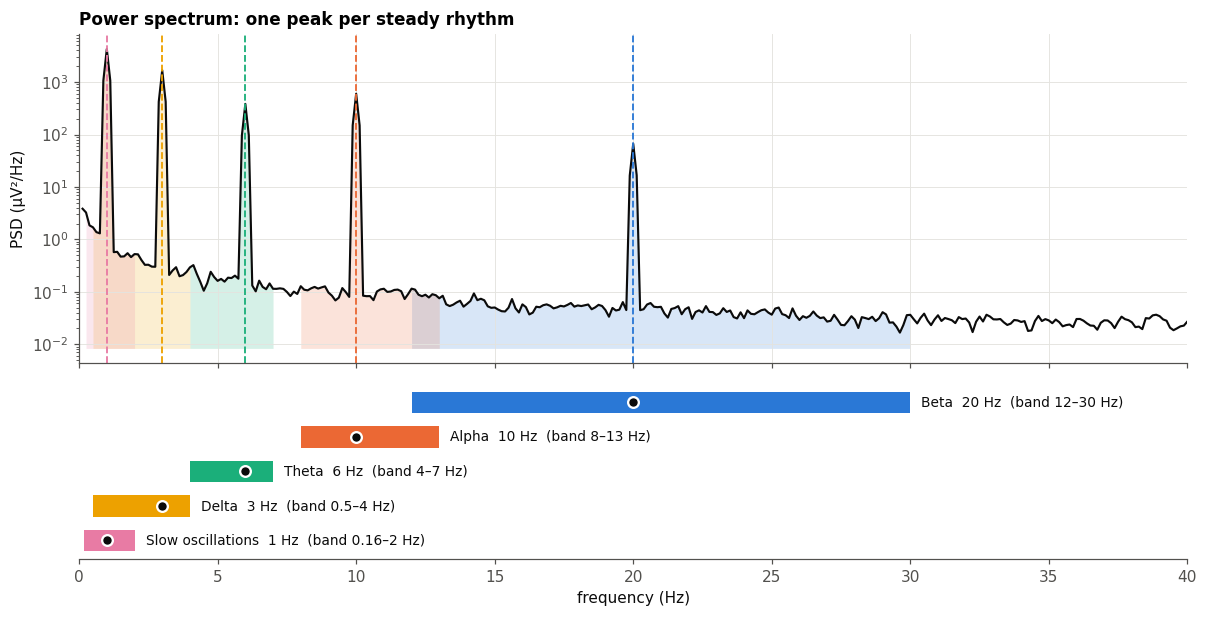

In [35]:
f, pxx = welch(band_mix, fs=FS, nperseg=int(PSD_WINDOW_S * FS))
keep = (f > 0) & (f <= PSD_FMAX_HZ)

fig = plt.figure(figsize=(FIG_WIDTH, 6.2))
gs = GridSpec(2, 1, height_ratios=[3, 1.6], hspace=0.08, figure=fig)
ax = fig.add_subplot(gs[0]); axb = fig.add_subplot(gs[1], sharex=ax)

ax.semilogy(f[keep], pxx[keep], color=COLORS["text"], lw=1.4)
for name in names:
    lo, hi = BANDS[name]["range"]
    m = keep & (f >= lo) & (f <= hi)
    ax.fill_between(f[m], pxx[m], pxx[keep].min() * 0.5, color=COLORS[name], alpha=0.18, lw=0)
    ax.axvline(BANDS[name]["freq_hz"], color=COLORS[name], ls="--", lw=1.2)
ax.set_ylabel("PSD (µV²/Hz)")
ax.set_title("Power spectrum: one peak per steady rhythm", loc="left")
plt.setp(ax.get_xticklabels(), visible=False)

for i, name in enumerate(names):
    lo, hi = BANDS[name]["range"]
    y = len(names) - 1 - i
    axb.barh(y, hi - lo, left=lo, height=0.62, color=COLORS[name])
    axb.plot(BANDS[name]["freq_hz"], y, "o", ms=7, color=COLORS["text"], mec="white", mew=1.5)
    axb.text(hi + 0.4, y, f"{name}  {BANDS[name]['freq_hz']:g} Hz  (band {lo:g}–{hi:g} Hz)", va="center", color=COLORS["text"], fontsize=FONT_SIZE - 1)
axb.set_yticks([]); axb.grid(False)
axb.set_xlabel("frequency (Hz)")
axb.set_xlim(0, PSD_FMAX_HZ)
axb.spines["left"].set_visible(False)
save(fig, "A2_band_spectrum")
plt.show()

## A3 · Relative band power

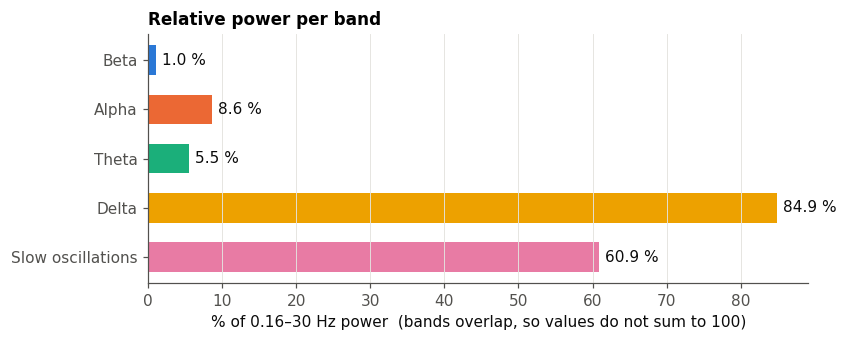

In [36]:
total = np.trapezoid(pxx[(f >= 0.16) & (f <= 30)], f[(f >= 0.16) & (f <= 30)])
rel = []
for name in names:
    lo, hi = BANDS[name]["range"]
    m = (f >= lo) & (f <= hi)
    rel.append(100 * np.trapezoid(pxx[m], f[m]) / total)

fig, ax = plt.subplots(figsize=(FIG_WIDTH * 0.6, 3.2))
bars = ax.barh(names[::-1], rel[::-1], color=[COLORS[n] for n in names[::-1]], height=0.6)
for b, v in zip(bars, rel[::-1]):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f} %", va="center", color=COLORS["text"])
ax.set_xlabel("% of 0.16–30 Hz power  (bands overlap, so values do not sum to 100)")
ax.grid(axis="y", visible=False)
ax.set_title("Relative power per band", loc="left")
fig.tight_layout(); save(fig, "A3_relative_power"); plt.show()

# Part B · Hierarchical nesting during NREM sleep
**Slow oscillation up-state → thalamocortical spindle → hippocampal ripple in spindle trough**

Pipeline (identical for simulated and real data):
1. SO band (`SO_LOW_HZ`–2 Hz) → Hilbert phase. Phase is referenced so that **0° = up-state peak** and ±180° = down-state.
2. Spindle band (13–16 Hz) → Hilbert amplitude (detection) and phase (**0° = peak, ±180° = trough**).
3. Ripple band (80–200 Hz) on the hippocampal channel → Hilbert amplitude → detection.
4. Coupling: SO phase at each spindle peak; spindle phase at each ripple peak; phase–amplitude modulation index.

## B0 · Triple coupling, step by step: SO → spindle → ripple
A noise-free schematic of **one** nested event, built the same way the coupling is measured in real data:

1. **Original data** = slow oscillation + spindle + ripple.
2. **SW filtered** (`SO_LOW_HZ`–2 Hz): the slow-wave (SW) peak is the depolarizing **up-state** and defines **0°** of SW phase
   (SW negative peak = down-state = ±180°).
3. **Spindle filtered** (13–16 Hz): the peak of its Hilbert envelope is the spindle **event centre**. Its SW phase is the
   **SO–spindle coupling phase** (grey band; −40° here = spindle peaks shortly *before* the SW peak).
4. **Ripple filtered** (80–200 Hz): the peak of the ripple envelope is the ripple event centre.
5. **Zoom** (bottom): within the spindle, the spindle's own phase is the reference (0° = spindle peak, ±180° = trough).
   The spindle phase at the ripple centre is the **spindle–ripple coupling phase**, ≈ ±180° = the ripple sits in a **trough**.

The coupling phases printed in the figure are **measured** from the filtered signals with the Hilbert transform, not copied
from the settings, so you can check the pipeline. Change `TRIPLE_*` in the settings to move the events.

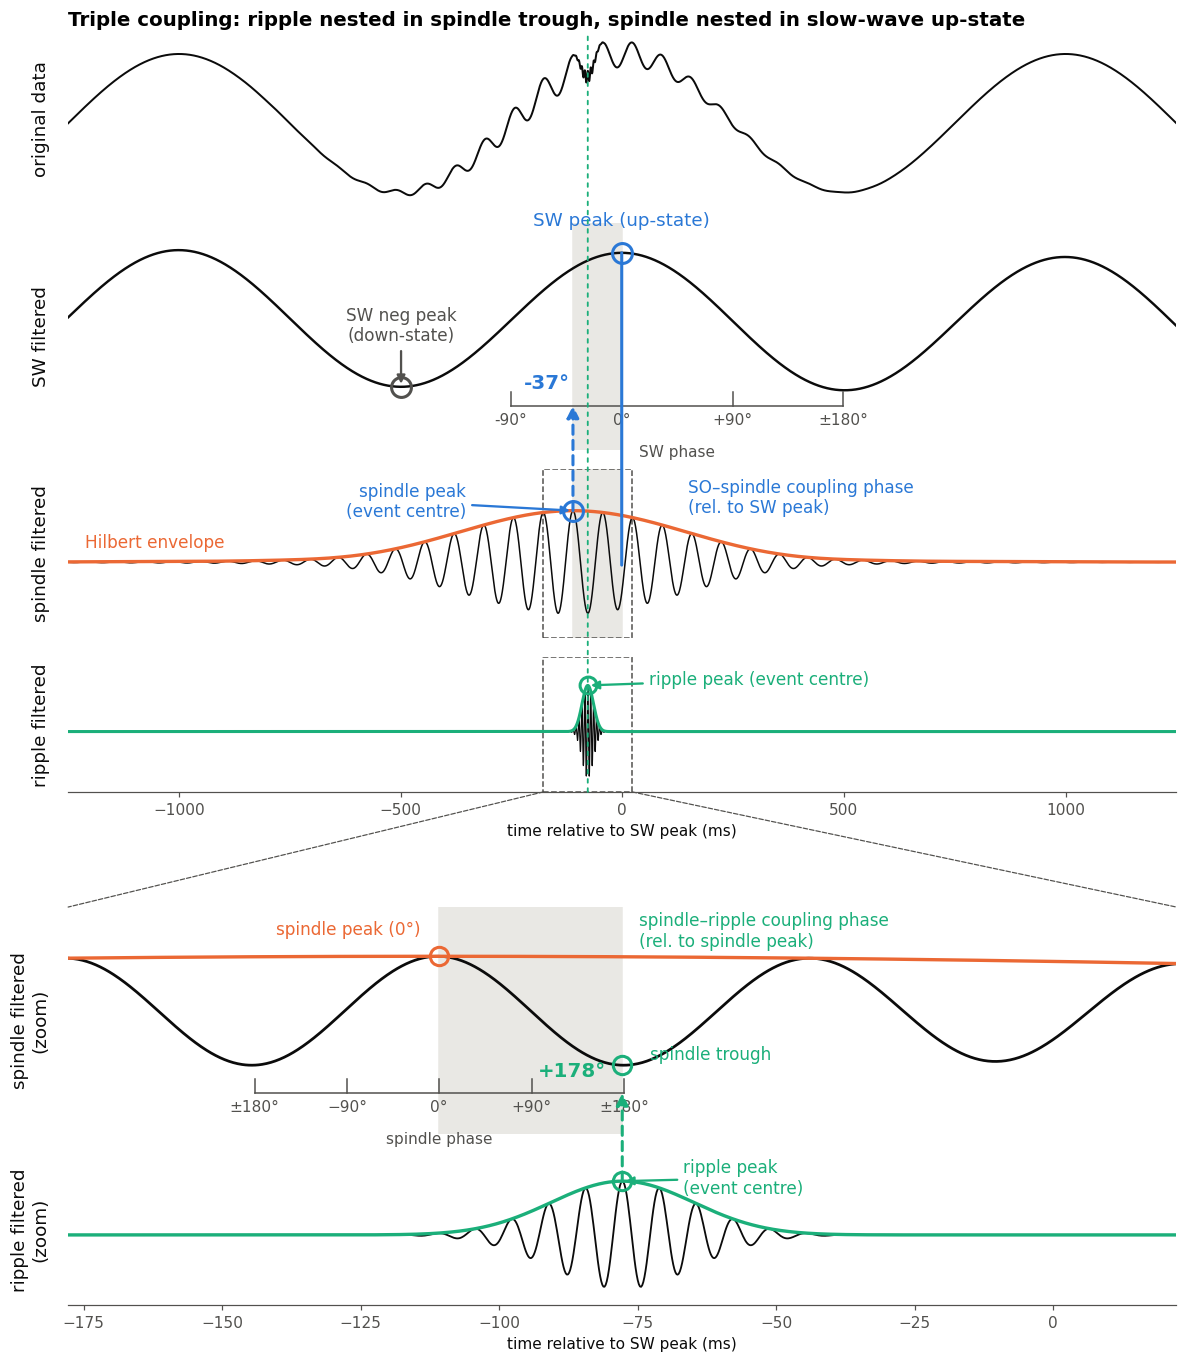

measured SO phase at spindle peak : -36.6°  (set -40°)
measured spindle phase at ripple  : +178.4°  (set +180°; ±180° = trough)


In [37]:
# ---- noise-free schematic signal, long enough to avoid filter edge effects ----
FS_SCHEM = 5000                                                         # high rate: smooth 150 Hz drawing
ts = np.arange(-6, 6, 1 / FS_SCHEM)
c_sp = TRIPLE_SPINDLE_LAG_DEG / 360 / SO_FREQ_HZ                       # spindle centre (s)
t_rp = c_sp + (TRIPLE_RIPPLE_SPINDLE_PHASE_DEG / 360 + TRIPLE_RIPPLE_CYCLE) / SPINDLE_FREQ_HZ
g = lambda t0, fwhm: np.exp(-(ts - t0) ** 2 / (2 * (fwhm / 2.3548) ** 2))
so_c = TRIPLE_SO_AMP_UV * np.cos(2 * np.pi * SO_FREQ_HZ * ts)          # SW peak (up-state) at t = 0
sp_c = TRIPLE_SPINDLE_AMP_UV * g(c_sp, TRIPLE_SPINDLE_FWHM_S) * np.cos(2 * np.pi * SPINDLE_FREQ_HZ * (ts - c_sp))
rp_c = TRIPLE_RIPPLE_AMP_UV * g(t_rp, TRIPLE_RIPPLE_FWHM_S) * np.cos(2 * np.pi * RIPPLE_FREQ_HZ * (ts - t_rp))
raw_c = so_c + sp_c + rp_c

# ---- the measurement pipeline ----
sw_f = bandpass(raw_c, SO_LOW_HZ, 2.0, fs=FS_SCHEM);       sw_ph = np.angle(hilbert(sw_f))
spf = bandpass(raw_c, *SPINDLE_BAND, fs=FS_SCHEM);         spa = hilbert(spf); spf_env, spf_ph = np.abs(spa), np.angle(spa)
rpf = bandpass(raw_c, *RIPPLE_BAND, fs=FS_SCHEM);          rpf_env = np.abs(hilbert(rpf))

half = 1.25 / SO_FREQ_HZ
win = (ts >= -half) & (ts <= half)
iw = np.flatnonzero(win)
i_swpk = iw[np.argmax(np.where(np.abs(ts[iw]) < 0.5 / SO_FREQ_HZ, sw_f[iw], -np.inf))]
i_swneg = iw[np.argmin(np.where((ts[iw] < ts[i_swpk]) & (ts[iw] > ts[i_swpk] - 1 / SO_FREQ_HZ), sw_f[iw], np.inf))]
i_sp = iw[np.argmax(spf_env[iw])]
i_rp = iw[np.argmax(rpf_env[iw])]
ph_so_sp = np.rad2deg(sw_ph[i_sp])          # SO phase at spindle peak
ph_sp_rp = np.rad2deg(spf_ph[i_rp])         # spindle phase at ripple peak
ms = lambda i: ts[i] * 1000

# ---- figure ----
cSO, cSP, cRP, cK, cM = COLORS["so"], COLORS["spindle"], COLORS["ripple"], COLORS["text"], COLORS["muted"]
fig = plt.figure(figsize=(FIG_WIDTH, 15))
gs = GridSpec(7, 1, height_ratios=[1.0, 1.35, 1.0, 0.8, 0.45, 1.35, 0.9], hspace=0.12, figure=fig)
axA, axB, axC, axD = (fig.add_subplot(gs[i]) for i in range(4))
axE, axF = fig.add_subplot(gs[5]), fig.add_subplot(gs[6])
for ax in (axA, axB, axC, axD, axE, axF):
    ax.grid(False); ax.set_yticks([])
    for sp_ in ("left", "top", "right"):
        ax.spines[sp_].set_visible(False)
for ax in (axA, axB, axC):
    ax.spines["bottom"].set_visible(False); ax.set_xticks([])
for ax in (axA, axB, axC, axD):
    ax.set_xlim(-half * 1000, half * 1000)
T = ts * 1000

def ylab(ax, text):
    ax.set_ylabel(text, rotation=90, fontsize=FONT_SIZE + 2, color=cK, labelpad=12)

def phase_axis(ax, t0_ms, period_ms, y, color, title, ticks=(-90, 0, 90, 180), ticklabels=None):
    """Draw a phase ruler: 0° at t0_ms, one full cycle = period_ms."""
    xs = [t0_ms + p / 360 * period_ms for p in ticks]
    ax.plot([min(xs), max(xs)], [y, y], color=color, lw=1)
    rngy = np.diff(ax.get_ylim())[0]
    for x, p, lab in zip(xs, ticks, ticklabels or [f"{p:+d}°" if p not in (0, 180, -180) else ("0°" if p == 0 else "±180°") for p in ticks]):
        ax.plot([x, x], [y, y + 0.06 * rngy], color=color, lw=1)
        ax.text(x, y - 0.03 * rngy, lab, ha="center", va="top", color=color, fontsize=FONT_SIZE)
    ax.text((min(xs) + max(xs)) / 2, y - 0.17 * rngy, title, ha="center", va="top", color=color, fontsize=FONT_SIZE)

# A · original data
axA.plot(T[win], raw_c[win], color=cK, lw=1.3); ylab(axA, "original data")
axA.set_title("Triple coupling: ripple nested in spindle trough, spindle nested in slow-wave up-state",
              loc="left", fontsize=FONT_SIZE + 3)

# B · SW filtered
axB.plot(T[win], sw_f[win], color=cK, lw=1.6); ylab(axB, "SW filtered")
axB.set_ylim(-TRIPLE_SO_AMP_UV * 1.9, TRIPLE_SO_AMP_UV * 1.45)
axB.plot(ms(i_swpk), sw_f[i_swpk], "o", ms=13, mfc="none", mec=cSO, mew=2)
axB.annotate("SW peak (up-state)", (ms(i_swpk), sw_f[i_swpk]), xytext=(0, 18), textcoords="offset points",
             ha="center", color=cSO, fontsize=FONT_SIZE + 2)
axB.plot(ms(i_swneg), sw_f[i_swneg], "o", ms=13, mfc="none", mec=cM, mew=2)
axB.annotate("SW neg peak\n(down-state)", (ms(i_swneg), sw_f[i_swneg]), xytext=(0, 30), textcoords="offset points",
             ha="center", color=cM, fontsize=FONT_SIZE + 1, arrowprops=dict(arrowstyle="-|>", color=cM, lw=1.5))
y_ax = -TRIPLE_SO_AMP_UV * 1.25
phase_axis(axB, ms(i_swpk), 1000 / SO_FREQ_HZ, y_ax, cM, "SW phase")

# C · spindle filtered
axC.plot(T[win], spf[win], color=cK, lw=1.0); ylab(axC, "spindle filtered")
axC.plot(T[win], spf_env[win], color=cSP, lw=2.2)
axC.text(-half * 1000 * 0.97, TRIPLE_SPINDLE_AMP_UV * 0.25, "Hilbert envelope", color=cSP, fontsize=FONT_SIZE + 1)
axC.set_ylim(-TRIPLE_SPINDLE_AMP_UV * 1.3, TRIPLE_SPINDLE_AMP_UV * 1.6)
axC.plot(ms(i_sp), spf_env[i_sp], "o", ms=13, mfc="none", mec=cSO, mew=2)
axC.annotate("spindle peak\n(event centre)", (ms(i_sp), spf_env[i_sp]), xytext=(-70, 6), textcoords="offset points",
             ha="right", va="center", color=cSO, fontsize=FONT_SIZE + 1, arrowprops=dict(arrowstyle="-|>", color=cSO, lw=1.5))

# D · ripple filtered
axD.plot(T[win], rpf[win], color=cK, lw=0.8); ylab(axD, "ripple filtered")
axD.plot(T[win], rpf_env[win], color=cRP, lw=2)
axD.set_ylim(-TRIPLE_RIPPLE_AMP_UV * 1.3, TRIPLE_RIPPLE_AMP_UV * 1.6)
axD.plot(ms(i_rp), rpf_env[i_rp], "o", ms=11, mfc="none", mec=cRP, mew=2)
axD.annotate("ripple peak (event centre)", (ms(i_rp), rpf_env[i_rp]), xytext=(40, 4), textcoords="offset points",
             ha="left", va="center", color=cRP, fontsize=FONT_SIZE + 1, arrowprops=dict(arrowstyle="-|>", color=cRP, lw=1.5))
axD.set_xlabel("time relative to SW peak (ms)")

# SO -> spindle coupling: SW-peak line, spindle-peak arrow to the SW phase ruler, grey band
for ax in (axB, axC):
    ax.axvspan(min(ms(i_sp), ms(i_swpk)), max(ms(i_sp), ms(i_swpk)), color=COLORS["band"], zorder=0)
fig.add_artist(ConnectionPatch((ms(i_swpk), spf_env[i_swpk] * 0 - TRIPLE_SPINDLE_AMP_UV * 0.05), (ms(i_swpk), sw_f[i_swpk]),
                               "data", "data", axesA=axC, axesB=axB, color=cSO, lw=2))
fig.add_artist(ConnectionPatch((ms(i_sp), spf_env[i_sp]), (ms(i_sp), y_ax), "data", "data", axesA=axC, axesB=axB,
                               color=cSO, lw=2, ls=(0, (3, 2)), arrowstyle="-|>", mutation_scale=16))
axB.text(ms(i_sp) - 8, y_ax + 0.25 * TRIPLE_SO_AMP_UV, f"{ph_so_sp:+.0f}°", ha="right", color=cSO,
         fontsize=FONT_SIZE + 3, fontweight="bold")
axC.text(max(ms(i_sp), ms(i_swpk)) + 0.12 * half * 1000, TRIPLE_SPINDLE_AMP_UV * 1.45, "SO–spindle coupling phase\n(rel. to SW peak)",
         color=cSO, fontsize=FONT_SIZE + 1, va="top")

# ripple time across the full-window rows
fig.add_artist(ConnectionPatch((ms(i_rp), -TRIPLE_RIPPLE_AMP_UV * 1.3), (ms(i_rp), axA.get_ylim()[1]), "data", "data",
                               axesA=axD, axesB=axA, color=cRP, lw=1.2, ls=(0, (2, 3))))

# ---- zoom: spindle phase at the ripple ----
z0, z1 = ms(i_rp) - TRIPLE_ZOOM_MS, ms(i_rp) + TRIPLE_ZOOM_MS
zm = (T >= z0) & (T <= z1)
for ax in (axC, axD):
    ax.add_patch(Rectangle((z0, ax.get_ylim()[0]), z1 - z0, np.diff(ax.get_ylim())[0], fc="none", ec=cM, lw=1, ls="--"))
for ax in (axE, axF):
    ax.set_xlim(z0, z1)
axE.spines["bottom"].set_visible(False); axE.set_xticks([])
axE.plot(T[zm], spf[zm], color=cK, lw=1.8); axE.plot(T[zm], spf_env[zm], color=cSP, lw=2.2)
amp_z = spf_env[zm].max()
axE.set_ylim(-amp_z * 2.25, amp_z * 1.9); ylab(axE, "spindle filtered\n(zoom)")
for x in (z0, z1):   # zoom connectors from the full-window rows to the close-up
    fig.add_artist(ConnectionPatch((x, axD.get_ylim()[0]), (x, axE.get_ylim()[1]), "data", "data",
                                   axesA=axD, axesB=axE, color=cM, lw=0.8, ls="--"))
pk_ms = ms(i_rp) - ph_sp_rp / 360 * 1000 / SPINDLE_FREQ_HZ           # spindle peak preceding the ripple (0°)
y_ph = -amp_z * 1.5
ticks = (-180, -90, 0, 90, 180)
phase_axis(axE, pk_ms, 1000 / SPINDLE_FREQ_HZ, y_ph, cM, "spindle phase", ticks=ticks,
           ticklabels=["±180°", "−90°", "0°", "+90°", "±180°"])
i_pk = np.argmin(np.abs(T - pk_ms))
axE.plot(pk_ms, spf[i_pk], "o", ms=12, mfc="none", mec=cSP, mew=2)
axE.annotate("spindle peak (0°)", (pk_ms, spf[i_pk]), xytext=(-12, 14), textcoords="offset points", ha="right",
             color=cSP, fontsize=FONT_SIZE + 1)
axE.plot(ms(i_rp), spf[i_rp], "o", ms=12, mfc="none", mec=cRP, mew=2)
axE.annotate("spindle trough", (ms(i_rp), spf[i_rp]), xytext=(18, 4), textcoords="offset points", ha="left",
             color=cRP, fontsize=FONT_SIZE + 1)
axE.axvspan(min(pk_ms, ms(i_rp)), max(pk_ms, ms(i_rp)), color=COLORS["band"], zorder=0)
axE.text(max(pk_ms, ms(i_rp)) + 3, amp_z * 1.82, "spindle–ripple coupling phase\n(rel. to spindle peak)",
         color=cRP, fontsize=FONT_SIZE + 1, va="top", ha="left")

axF.plot(T[zm], rpf[zm], color=cK, lw=1.2); axF.plot(T[zm], rpf_env[zm], color=cRP, lw=2.2)
axF.set_ylim(-TRIPLE_RIPPLE_AMP_UV * 1.3, TRIPLE_RIPPLE_AMP_UV * 1.5); ylab(axF, "ripple filtered\n(zoom)")
axF.plot(ms(i_rp), rpf_env[i_rp], "o", ms=12, mfc="none", mec=cRP, mew=2)
axF.annotate("ripple peak\n(event centre)", (ms(i_rp), rpf_env[i_rp]), xytext=(40, 2), textcoords="offset points",
             ha="left", va="center", color=cRP, fontsize=FONT_SIZE + 1, arrowprops=dict(arrowstyle="-|>", color=cRP, lw=1.5))
axF.set_xlabel("time relative to SW peak (ms)")
fig.add_artist(ConnectionPatch((ms(i_rp), rpf_env[i_rp]), (ms(i_rp), y_ph), "data", "data", axesA=axF, axesB=axE,
                               color=cRP, lw=2, ls=(0, (3, 2)), arrowstyle="-|>", mutation_scale=16))
axE.text(ms(i_rp) - 3, y_ph + 0.3 * amp_z, f"{ph_sp_rp:+.0f}°", ha="right", color=cRP, fontsize=FONT_SIZE + 3, fontweight="bold")

save(fig, "B0_triple_coupling_schematic"); plt.show()
print(f"measured SO phase at spindle peak : {ph_so_sp:+.1f}°  (set {TRIPLE_SPINDLE_LAG_DEG:+d}°)")
print(f"measured spindle phase at ripple  : {ph_sp_rp:+.1f}°  (set {TRIPLE_RIPPLE_SPINDLE_PHASE_DEG:+d}°; ±180° = trough)")

In [38]:
so_f = bandpass(cortex, SO_LOW_HZ, 2.0)
so_phase = np.angle(hilbert(UP_STATE_POLARITY * so_f))        # 0 = up-state peak
up_state = UP_STATE_POLARITY * so_f > 0

sp_f = bandpass(cortex, *SPINDLE_BAND)
sp_an = hilbert(sp_f)
sp_env = smooth(np.abs(sp_an), SPINDLE_SMOOTH_S)
sp_phase = np.angle(sp_an)                                     # 0 = peak, ±π = trough

rp_f = bandpass(hpc, *RIPPLE_BAND)
rp_env = smooth(np.abs(hilbert(rp_f)), RIPPLE_SMOOTH_S)

spindles_det, sp_thr = detect_events(sp_env, SPINDLE_THRESH_K, SPINDLE_MIN_DUR_S, SPINDLE_MAX_DUR_S)
ripples_det, rp_thr = detect_events(rp_env, RIPPLE_THRESH_K, RIPPLE_MIN_DUR_S)
sp_peaks = np.array([p for _, _, p in spindles_det], dtype=int)
# ripple centre = largest absolute ripple-band deflection inside the event
rp_peaks = np.array([s + int(np.argmax(np.abs(rp_f[s:e]))) for s, e, _ in ripples_det], dtype=int)

in_spindle = np.zeros_like(cortex, dtype=bool)
for s, e, _ in spindles_det:
    in_spindle[s:e] = True
rp_in_sp = rp_peaks[in_spindle[rp_peaks]] if rp_peaks.size else rp_peaks

print(f"detected {len(spindles_det)} spindles, {len(ripples_det)} ripples "
      f"({len(rp_in_sp)} inside spindles)")

detected 28 spindles, 117 ripples (117 inside spindles)


## B1 · Overview: the three rhythms over time

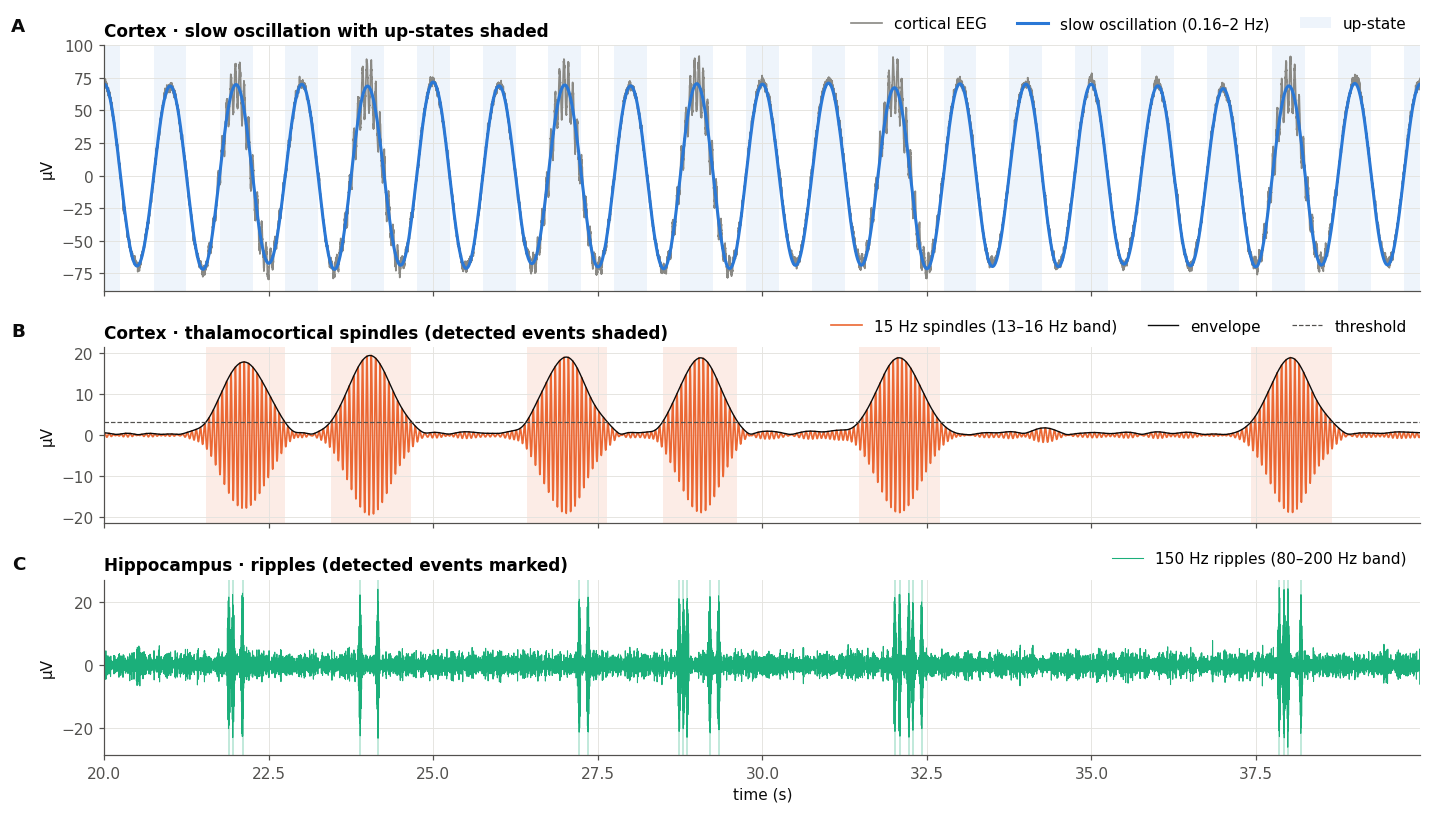

In [39]:
a, b = (int(x * FS) for x in OVERVIEW_WINDOW_S)
tw = t[a:b]
fig, axes = plt.subplots(3, 1, figsize=(FIG_WIDTH, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.4, 1, 1]})

ax = axes[0]
ax.plot(tw, cortex[a:b], color=COLORS["raw"], label="cortical EEG")
ax.plot(tw, so_f[a:b], color=COLORS["so"], lw=2, label=f"slow oscillation ({SO_LOW_HZ:g}–2 Hz)")
ylim = ax.get_ylim()
ax.fill_between(tw, *ylim, where=up_state[a:b], color=COLORS["so"], alpha=0.08, lw=0, label="up-state")
ax.set_ylim(ylim); ax.set_ylabel("µV"); ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3)
ax.set_title("Cortex · slow oscillation with up-states shaded", loc="left")

ax = axes[1]
ax.plot(tw, sp_f[a:b], color=COLORS["spindle"], label=f"{SPINDLE_FREQ_HZ:g} Hz spindles (13–16 Hz band)")
ax.plot(tw, sp_env[a:b], color=COLORS["text"], lw=0.9, label="envelope")
ax.axhline(sp_thr, color=COLORS["muted"], ls="--", lw=0.8, label="threshold")
for s, e, _ in spindles_det:
    if s < b and e > a:
        ax.axvspan(t[s], t[e - 1], color=COLORS["spindle"], alpha=0.12, lw=0)
ax.set_ylabel("µV"); ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3)
ax.set_title("Cortex · thalamocortical spindles (detected events shaded)", loc="left")

ax = axes[2]
ax.plot(tw, rp_f[a:b], color=COLORS["ripple"], lw=0.7, label=f"{RIPPLE_FREQ_HZ:g} Hz ripples (80–200 Hz band)")
for p in rp_peaks[(rp_peaks >= a) & (rp_peaks < b)]:
    ax.axvline(t[p], color=COLORS["ripple"], alpha=0.35, lw=1)
ax.set_ylabel("µV"); ax.set_xlabel("time (s)"); ax.legend(loc="lower right", bbox_to_anchor=(1, 1))
ax.set_title("Hippocampus · ripples (detected events marked)", loc="left")
ax.set_xlim(tw[0], tw[-1])
for i, ax in enumerate(axes):
    label_panel(ax, "ABC"[i])
fig.tight_layout(); save(fig, "B1_overview"); plt.show()

## B2 · Zoom into one nested event
Upper three rows: one slow oscillation cycle (±1.5 s). Lower two rows: a 300 ms close-up around the ripple, showing that the
ripple sits in a **trough** of the spindle (dashed lines mark ripple centres).

In [ ]:
# pick events: a ripple inside a spindle whose peak lies in an up-state
cands = [r for r in rp_in_sp if up_state[r]] or list(rp_in_sp) or list(rp_peaks)
if not cands:
    raise RuntimeError("no ripple detected – lower RIPPLE_THRESH_K")
r0 = cands[min(ZOOM_EVENT, len(cands) - 1)]
# centre the long window on the nearest up-state peak
up_idx = np.flatnonzero(np.diff(np.sign(np.diff(UP_STATE_POLARITY * so_f))) < 0) + 1
c0 = up_idx[np.argmin(np.abs(up_idx - r0))]
A, B = c0 - int(1.5 * FS), c0 + int(1.5 * FS)
za, zb = r0 - int(0.15 * FS), r0 + int(0.15 * FS)
rip_here = rp_peaks[(rp_peaks >= A) & (rp_peaks < B)]

fig = plt.figure(figsize=(FIG_WIDTH, 9.5))
gs = GridSpec(5, 1, height_ratios=[1.3, 1, 1, 1, 1], hspace=0.55, figure=fig)
ax1 = fig.add_subplot(gs[0]); ax2 = fig.add_subplot(gs[1], sharex=ax1); ax3 = fig.add_subplot(gs[2], sharex=ax1)
ax4 = fig.add_subplot(gs[3]); ax5 = fig.add_subplot(gs[4], sharex=ax4)
T = (t[A:B] - t[c0]) * 1000; TZ = (t[za:zb] - t[r0]) * 1000

ax1.plot(T, cortex[A:B], color=COLORS["raw"], label="cortical EEG")
ax1.plot(T, so_f[A:B], color=COLORS["so"], lw=2.2, label="SO")
yl = ax1.get_ylim()
ax1.fill_between(T, *yl, where=up_state[A:B], color=COLORS["so"], alpha=0.08, lw=0, label="up-state")
ax1.set_ylim(yl); ax1.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3); ax1.set_ylabel("µV")
ax1.set_title(f"Slow oscillation ({SO_FREQ_HZ:g} Hz): depolarizing up-state", loc="left")

ax2.plot(T, sp_f[A:B], color=COLORS["spindle"]); ax2.plot(T, np.abs(sp_an[A:B]), color=COLORS["text"], lw=0.8)
ax2.set_ylabel("µV"); ax2.set_title(f"Spindle ({SPINDLE_FREQ_HZ:g} Hz) rides on the up-state", loc="left")

ax3.plot(T, rp_f[A:B], color=COLORS["ripple"], lw=0.7)
ax3.set_ylabel("µV"); ax3.set_xlabel("time from up-state peak (ms)")
ax3.set_title(f"Hippocampal ripples ({RIPPLE_FREQ_HZ:g} Hz) cluster during the spindle", loc="left")
for ax in (ax2, ax3):
    ax.axvspan((t[za] - t[c0]) * 1000, (t[zb] - t[c0]) * 1000, color=COLORS["grid"], alpha=0.8, lw=0, zorder=0)

ax4.plot(TZ, sp_f[za:zb], color=COLORS["spindle"], lw=1.8)
ax4.set_ylabel("µV"); ax4.set_title("Close-up · spindle cycles (grey window above)", loc="left")
ax5.plot(TZ, rp_f[za:zb], color=COLORS["ripple"], lw=1)
ax5.set_ylabel("µV"); ax5.set_xlabel("time from ripple centre (ms)")
ax5.set_title("Close-up · ripple aligned to a spindle trough", loc="left")
for rp in rip_here:
    if za <= rp < zb:
        for ax in (ax4, ax5):
            ax.axvline((t[rp] - t[r0]) * 1000, color=COLORS["muted"], ls="--", lw=0.9)
ax4.set_xlim(TZ[0], TZ[-1]); ax1.set_xlim(T[0], T[-1])
for i, ax in enumerate((ax1, ax2, ax3, ax4, ax5)):
    label_panel(ax, "ABCDE"[i])
save(fig, "B2_nested_event_zoom"); plt.show()

## B3 · Coupling statistics
* **A–C · SO → spindle:** grand average of the raw cortical signal locked to spindle peaks (the SO up-state appears around 0 with the spindle superimposed),
  the SO phase at each spindle peak, and spindle amplitude as a function of SO phase.
* **D–F · spindle → ripple:** ripple-locked average of the spindle-band signal (a trough at 0 ms means ripples occur in spindle troughs),
  the spindle phase at each ripple, and ripple amplitude as a function of spindle phase (samples inside spindles only).

Phase conventions: SO 0° = up-state peak; spindle 0° = peak, ±180° = trough.

In [ ]:
def polar_hist(ax, ph, color, title, zero_label, pi_label):
    edges = np.linspace(-np.pi, np.pi, PHASE_BINS + 1)
    cnt, _ = np.histogram(ph, edges)
    ax.bar((edges[:-1] + edges[1:]) / 2, cnt, width=2 * np.pi / PHASE_BINS * 0.92,
           color=color, alpha=0.85, edgecolor="white", linewidth=1)
    mu, R, p = circ_stats(ph)
    ax.annotate("", xy=(mu, R * cnt.max()), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=COLORS["text"], lw=2))
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_xticks(np.deg2rad([0, 90, 180, 270]))
    ax.set_xticklabels([zero_label, "90°", pi_label, "-90°"])
    ax.set_yticklabels([]); ax.grid(color=COLORS["grid"])
    ax.set_title(f"{title}\nmean {np.rad2deg(mu):.0f}°, R = {R:.2f}, n = {len(ph)}, "
                 f"Rayleigh p = {p:.1e}", fontsize=FONT_SIZE, pad=14)
    return mu, R, p

fig = plt.figure(figsize=(FIG_WIDTH, 9))
gs = GridSpec(2, 3, figure=fig, wspace=0.38, hspace=0.6)

# --- SO -> spindle ---
ax = fig.add_subplot(gs[0, 0])
lag, segs = peri_event(cortex, sp_peaks, SO_LOCK_WIN_S)
if len(segs):
    m, se = segs.mean(0), segs.std(0) / np.sqrt(len(segs))
    ax.fill_between(lag, m - se, m + se, color=COLORS["so"], alpha=0.2, lw=0)
    ax.plot(lag, m, color=COLORS["so"])
ax.axvline(0, color=COLORS["muted"], ls="--", lw=0.8)
ax.set_xlabel("time from spindle peak (s)"); ax.set_ylabel("µV")
ax.set_title("Spindle-locked cortical average", loc="left"); label_panel(ax, "A")

ax = fig.add_subplot(gs[0, 1], projection="polar")
so_at_sp = so_phase[sp_peaks]
so_stats = polar_hist(ax, so_at_sp, COLORS["spindle"], "SO phase at spindle peaks", "0°\nup-state", "±180°\ndown-state")
label_panel(ax, "B")

ax = fig.add_subplot(gs[0, 2])
mi_so, cen, amp = modulation_index(so_phase, sp_env)
ax.bar(np.rad2deg(cen), amp, width=360 / PHASE_BINS * 0.85, color=COLORS["spindle"])
ax.set_xticks([-180, -90, 0, 90, 180]); ax.set_xlabel("SO phase (°)   0 = up-state")
ax.set_ylabel("mean spindle amplitude (µV)")
ax.set_title(f"Spindle amplitude by SO phase\nMI = {mi_so:.4f}", loc="left"); label_panel(ax, "C")
ax.grid(axis="x", visible=False)

# --- spindle -> ripple ---
ax = fig.add_subplot(gs[1, 0])
lag, segs = peri_event(sp_f, rp_in_sp, RIPPLE_LOCK_WIN_S)
if len(segs):
    m, se = segs.mean(0), segs.std(0) / np.sqrt(len(segs))
    ax.fill_between(lag * 1000, m - se, m + se, color=COLORS["spindle"], alpha=0.2, lw=0)
    ax.plot(lag * 1000, m, color=COLORS["spindle"])
ax.axvline(0, color=COLORS["muted"], ls="--", lw=0.8)
ax.set_xlabel("time from ripple centre (ms)"); ax.set_ylabel("µV")
ax.set_title("Ripple-locked spindle-band average", loc="left"); label_panel(ax, "D")

ax = fig.add_subplot(gs[1, 1], projection="polar")
sp_at_rp = sp_phase[rp_in_sp]
sp_stats = polar_hist(ax, sp_at_rp, COLORS["ripple"], "Spindle phase at ripples", "0°\npeak", "±180°\ntrough")
label_panel(ax, "E")

ax = fig.add_subplot(gs[1, 2])
mi_sp, cen, amp = modulation_index(sp_phase[in_spindle], rp_env[in_spindle])
ax.bar(np.rad2deg(cen), amp, width=360 / PHASE_BINS * 0.85, color=COLORS["ripple"])
ax.set_xticks([-180, -90, 0, 90, 180]); ax.set_xlabel("spindle phase (°)   ±180 = trough")
ax.set_ylabel("mean ripple amplitude (µV)")
ax.set_title(f"Ripple amplitude by spindle phase\nMI = {mi_sp:.4f}", loc="left"); label_panel(ax, "F")
ax.grid(axis="x", visible=False)

save(fig, "B3_coupling_statistics"); plt.show()

## B4 · Summary table

In [ ]:
import pandas as pd
summary = pd.DataFrame([
    {"coupling": "SO phase → spindle peak", "n events": len(so_at_sp),
     "preferred phase (°)": np.rad2deg(so_stats[0]), "resultant R": so_stats[1],
     "Rayleigh p": so_stats[2], "modulation index": mi_so,
     "expected": "≈ 0° (up-state)"},
    {"coupling": "spindle phase → ripple", "n events": len(sp_at_rp),
     "preferred phase (°)": np.rad2deg(sp_stats[0]), "resultant R": sp_stats[1],
     "Rayleigh p": sp_stats[2], "modulation index": mi_sp,
     "expected": "≈ ±180° (trough)"},
])
summary.style.format({"preferred phase (°)": "{:.0f}", "resultant R": "{:.2f}",
                      "Rayleigh p": "{:.1e}", "modulation index": "{:.4f}"}).hide(axis="index")

### Interpretation & caveats
* With the default settings the simulation reproduces the canonical picture: spindles peak near the SO **up-state (≈ 0°)** and ripples
  lock to the spindle **trough (≈ ±180°)**. Change `SPINDLE_LAG_SD_S`, `SPINDLE_PROB`, `RIPPLE_JITTER_S` or `UP_STATE_POLARITY`
  in the settings to see how the coupling statistics respond.
* Real data: restrict analysis to NREM (N2/N3) epochs, reject artefacts, and compare MI against a surrogate distribution
  (e.g. time-shifted amplitude) before interpreting it. Scalp EEG does not record hippocampal ripples — those need intracranial
  (depth/LFP) recordings; set `REAL_HPC_CH` accordingly.
* Polarity: on the scalp the up-state corresponds to the surface-positive half-wave; in intracranial/cortical-depth recordings it can be
  inverted. `UP_STATE_POLARITY` handles this.